### Setup and data

In [3]:
!pip install -q mediapipe tqdm

In [4]:
import os, sys, json, time, shutil, zipfile, warnings, urllib.request
from collections import defaultdict
import numpy as np, pandas as pd, cv2, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix
from tqdm.auto import tqdm
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); np.random.seed(42)

from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/SignSense_data'
WORK, PROC, OUT, MODELS = '/content/work', '/content/processed', '/content/results', '/content/results/models'
for d in (WORK, OUT, MODELS, f'{DRIVE_DIR}/results', f'{DRIVE_DIR}/models'): os.makedirs(d, exist_ok=True)
need = ['processed_metadata.csv', 'label_map.json', 'dynamic_landmarks.npz', 'control_gestures.csv', 'results/static_test_predictions.npz', 'results/dynamic_test_predictions.npz']
missing = [f for f in need if not os.path.exists(f'{DRIVE_DIR}/{f}')]
assert not missing, f'Missing in {DRIVE_DIR}: {missing}'
for f in need: shutil.copy(f'{DRIVE_DIR}/{f}', WORK)

meta = pd.read_csv(f'{WORK}/processed_metadata.csv'); imgs = meta[meta['media_type'] == 'image'].reset_index(drop=True)
lm = json.load(open(f'{WORK}/label_map.json')); STATIC, DYNAMIC = lm['static_classes'], lm['dynamic_classes']; NS = len(STATIC)
npz = np.load(f'{WORK}/dynamic_landmarks.npz'); Xv, Mv, split_v = npz['X'], npz['mask'], npz['split']; yv = (npz['y'] - NS).astype(int)
dev_v, te_v = np.isin(split_v, ['train', 'val']), split_v == 'test'
FEAT = [f'f{i}' for i in range(63)]
ctrl = pd.read_csv(f'{WORK}/control_gestures.csv')
print('Control gesture rows per person and label:'); display(ctrl.groupby(['person', 'label']).size().unstack(fill_value=0))
assert {'space', 'delete'} <= set(ctrl['label']), 'control_gestures.csv needs space and delete rows'

# Processed images (needed for the landmarks of letter images)
def processed_ok(): return os.path.isdir(PROC) and all(os.path.exists(os.path.join(PROC, p)) for p in imgs['processed_path'])
if not processed_ok():
    zp = f'{DRIVE_DIR}/processed_images.zip'; assert os.path.exists(zp), 'processed_images.zip missing on Drive'
    shutil.copy(zp, '/content/processed_images.zip')
    with zipfile.ZipFile('/content/processed_images.zip') as z: z.extractall(PROC)
assert processed_ok(); print('Processed images ready.')

Mounted at /content/drive
Control gesture rows per person and label:


label,delete,space
person,,
aamina,273,294
fahad,203,269
wisha,296,299


Processed images ready.


## 1. Typing engine module
The engine is written to a file so that exactly the same code is used here and in the web app. It is pure Python / NumPy (no TensorFlow). Download `typing_engine.py` from this notebook's file panel and keep it in the repo.

In [5]:
%%writefile /content/typing_engine.py
"""
SignSense typing engine: turns per-frame recognition events into Urdu text.

No TensorFlow dependency. Used by the pipeline notebook (simulation) and by the web app.

Pieces
    LETTER_MAP / CHAR_TO_CLASS  dataset class name <-> Urdu character
    Lexicon                     dictionary correction (edit distance) applied when a word ends
    TyperConfig / SignTyper     letter buffer, stability check, neutral requirement, space and delete gestures
    MotionRouter                splits a landmark stream into STILL (-> static model) and MOVING segments (-> dynamic model)
    resample_segment, dynamic_features   turn a moving segment into the feature vector of the dynamic Random Forest
    decide_event                fuses control-gesture and letter probabilities of one frame into one event
"""
from collections import defaultdict, deque
from dataclasses import dataclass
import numpy as np

# Dataset class name -> Urdu character. Derived from the class numbers in the dataset file names (01 ... 40),
# which follow the order of the Urdu alphabet.
LETTER_MAP = {
    'Alifmad': 'آ', 'Alif': 'ا', 'Bay': 'ب', 'Pay': 'پ', 'Tay': 'ت', 'Taay': 'ٹ', 'Say': 'ث', 'Jeem': 'ج',
    'Chay': 'چ', '1-Hay': 'ح', 'Khay': 'خ', 'Dal': 'د', 'Daal': 'ڈ', 'Zaal': 'ذ', 'Ray': 'ر', 'Aray': 'ڑ',
    'Zay': 'ز', 'Zaey': 'ژ', 'Seen': 'س', 'Sheen': 'ش', 'Suad': 'ص', 'Zuad': 'ض', 'Tuey': 'ط', 'Zuey': 'ظ',
    'Ain': 'ع', 'Ghain': 'غ', 'Fay': 'ف', 'Kaf': 'ق', 'Kiaf': 'ک', 'Gaaf': 'گ', 'Lam': 'ل', 'Meem': 'م',
    'Nuun': 'ن', 'Nuungh': 'ں', 'Wao': 'و', '2-Hay': 'ہ', 'Dochahay': 'ھ', 'Hamza': 'ء', 'Cyeh': 'ی', 'Byeh': 'ے'}
CHAR_TO_CLASS = {v: k for k, v in LETTER_MAP.items()}
ALPHABET = set(LETTER_MAP.values())
DYNAMIC_CLASSES = ['2-Hay', 'Alifmad', 'Aray', 'Jeem']
STATIC_CLASSES = sorted(set(LETTER_MAP) - set(DYNAMIC_CLASSES))


def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


class Lexicon:
    """Word list for correction. Only words made of the 40 dataset letters are kept."""
    def __init__(self, words, min_len=3):
        self.words = {w.strip() for w in words if w.strip() and set(w.strip()) <= ALPHABET}
        self.by_len = defaultdict(list)
        for w in self.words:
            self.by_len[len(w)].append(w)
        self.min_len = min_len

    def correct(self, word, max_dist=1):
        """Return (word, changed). Only an unambiguous closest word within max_dist replaces the input."""
        if len(word) < self.min_len or word in self.words:
            return word, False
        cands = []
        for L in range(len(word) - max_dist, len(word) + max_dist + 1):
            for w in self.by_len.get(L, []):
                d = edit_distance(word, w)
                if d <= max_dist:
                    cands.append((d, w))
        if not cands:
            return word, False
        cands.sort()
        best = [w for d, w in cands if d == cands[0][0]]
        return (best[0], True) if len(best) == 1 else (word, False)


@dataclass
class TyperConfig:
    letter_conf: float = 0.9       # minimum confidence of a static letter frame
    stable_frames: int = 8         # consecutive frames of the same letter needed to commit it
    dynamic_conf: float = 0.6      # minimum confidence of a dynamic-letter prediction (one-shot event)
    control_conf: float = 0.9      # minimum probability of a space / delete frame
    control_frames: int = 8        # consecutive frames needed to commit space / delete
    neutral_frames: int = 3        # consecutive 'no hand' frames that count as the neutral position
    require_neutral: str = 'same'  # 'same': the same letter twice needs a neutral gap; 'all': every letter does
    correct_words: bool = True     # dictionary correction when a word ends
    max_dist: int = 1


class SignTyper:
    def __init__(self, cfg=None, lexicon=None):
        self.cfg = cfg or TyperConfig()
        self.lexicon = lexicon
        self.reset()

    def reset(self):
        self.words = []            # finished words as (raw, final)
        self.current = []          # characters of the word being typed
        self.trailing_space = False
        self._cand, self._cand_n, self._locked, self._none_n = None, 0, None, 0

    # ---- text ----
    @property
    def text(self):
        parts = [final for _, final in self.words]
        if self.current:
            parts.append(''.join(self.current))
        s = ' '.join(parts)
        return s + (' ' if self.trailing_space else '')

    def final_text(self):
        """Finish the word in progress (with correction) and return the whole text."""
        if self.current:
            self._finish_word()
        return ' '.join(f for _, f in self.words)

    # ---- internals ----
    def _finish_word(self):
        raw = ''.join(self.current); final = raw
        if self.cfg.correct_words and self.lexicon is not None:
            final, _ = self.lexicon.correct(raw, self.cfg.max_dist)
        self.words.append((raw, final)); self.current = []
        return raw, final

    def _reset_candidate(self):
        self._cand, self._cand_n = None, 0

    def _commit(self, key):
        kind = key[0]
        if kind == 'letter':
            ch = LETTER_MAP[key[1]]; self.current.append(ch); self.trailing_space = False
            return {'action': 'letter', 'char': ch}
        if kind == 'space':
            if not self.current:
                return {'action': 'space_ignored'}
            raw, final = self._finish_word(); self.trailing_space = True
            return {'action': 'space', 'raw': raw, 'word': final, 'corrected': raw != final}
        if kind == 'delete':
            if self.current:
                return {'action': 'delete', 'char': self.current.pop()}
            if self.trailing_space and self.words:      # deleting the space re-opens the last word (as typed)
                raw, _ = self.words.pop(); self.current = list(raw); self.trailing_space = False
                return {'action': 'delete', 'char': ' '}
            return {'action': 'delete_ignored'}

    def _step_key(self, key, need):
        locked = self._locked
        if locked == key or (locked == 'ANY' and key[0] == 'letter'):
            self._reset_candidate(); return None
        if key == self._cand:
            self._cand_n += 1
        else:
            self._cand, self._cand_n = key, 1
        if self._cand_n >= need:
            self._reset_candidate()
            self._locked = 'ANY' if (key[0] == 'letter' and self.cfg.require_neutral == 'all') else key
            return self._commit(key)
        return None

    # ---- main entry point: call once per frame ----
    def step(self, kind, label=None, conf=0.0):
        """kind: 'none' (no hand) | 'letter' (static letter) | 'dynamic' (one-shot dynamic letter) | 'space' | 'delete'."""
        c = self.cfg
        if kind == 'none':
            self._none_n += 1; self._reset_candidate()
            if self._none_n >= c.neutral_frames:
                self._locked = None
            return None
        self._none_n = 0
        if kind == 'dynamic':
            self._reset_candidate()
            return self._commit(('letter', label)) if conf >= c.dynamic_conf else None
        if kind == 'letter':
            if conf < c.letter_conf:
                self._reset_candidate(); return None
            return self._step_key(('letter', label), c.stable_frames)
        if kind in ('space', 'delete'):
            if conf < c.control_conf:
                self._reset_candidate(); return None
            return self._step_key((kind,), c.control_frames)
        raise ValueError(kind)


def decide_event(hand_detected, p_space, p_delete, letter_probs, letter_names, control_conf=0.9):
    """One frame -> (kind, label, confidence). Control gestures take priority over letters."""
    if not hand_detected:
        return 'none', None, 0.0
    if p_space >= control_conf and p_space >= p_delete:
        return 'space', None, float(p_space)
    if p_delete >= control_conf:
        return 'delete', None, float(p_delete)
    i = int(np.argmax(letter_probs))
    return 'letter', letter_names[i], float(letter_probs[i])


def resample_segment(seg, T=88):
    """List/array of (63,) landmark vectors -> (X (T,63) float32, M (T,) bool), uniformly resampled like Phase 1."""
    seg = np.asarray(seg, np.float32)
    idx = np.linspace(0, len(seg) - 1, T).round().astype(int)
    return seg[idx], np.ones(T, bool)


def dynamic_features(X, M):
    """Same features as the dynamic Random Forest of Phase 2. X: (N,T,63), M: (N,T) bool -> (N, 508)."""
    X = np.asarray(X, np.float32); M = np.asarray(M, bool)
    F = np.concatenate([X, M[..., None].astype('float32')], axis=-1)
    V = np.zeros_like(X); V[:, 1:] = (X[:, 1:] - X[:, :-1]) * (M[:, 1:] & M[:, :-1])[..., None]
    F = np.concatenate([F, V], axis=-1).astype('float32')
    return np.concatenate([F.mean(1), F.std(1), F.min(1), F.max(1)], axis=1)


def window_extent(W):
    """Motion measure of a window of landmark vectors: largest RMS distance of any frame from the window mean."""
    W = np.asarray(W, np.float32)
    return float(np.sqrt(((W - W.mean(0)) ** 2).mean(1)).max())


class MotionRouter:
    """Streaming splitter. update(vec) -> (state, segment). vec = 63 normalized landmarks or None (no hand).
    state is 'none', 'still' or 'moving'; segment is an (n,63) array when a moving segment just ended."""
    def __init__(self, tau, window=10, still_frames=6, min_segment=12, max_segment=150):
        self.tau, self.window, self.still_frames = tau, window, still_frames
        self.min_segment, self.max_segment = min_segment, max_segment
        self.reset()

    def reset(self):
        self.buf = deque(maxlen=self.window); self.moving = False; self.seg = []; self.still_n = 0

    def _close(self):
        seg = self.seg[:len(self.seg) - self.still_n] if self.still_n else self.seg
        self.moving, self.seg, self.still_n = False, [], 0
        return np.asarray(seg, np.float32) if len(seg) >= self.min_segment else None

    def update(self, vec):
        if vec is None:
            out = self._close() if self.moving else None
            self.buf.clear()
            return 'none', out
        self.buf.append(np.asarray(vec, np.float32))
        if len(self.buf) < self.window:
            return ('moving' if self.moving else 'still'), None
        e = window_extent(self.buf)
        if not self.moving:
            if e > self.tau:
                self.moving = True; self.seg = list(self.buf); self.still_n = 0
                return 'moving', None
            return 'still', None
        self.seg.append(np.asarray(vec, np.float32))
        self.still_n = self.still_n + 1 if e <= self.tau else 0
        if self.still_n >= self.still_frames or len(self.seg) >= self.max_segment:
            return 'still', self._close()
        return 'moving', None

Writing /content/typing_engine.py


In [6]:
sys.path.insert(0, '/content')
import importlib, typing_engine as eng; importlib.reload(eng)
assert sorted(eng.STATIC_CLASSES) == sorted(STATIC) and sorted(eng.DYNAMIC_CLASSES) == sorted(DYNAMIC), 'class names differ from label_map.json'
print('Engine loaded.', len(eng.LETTER_MAP), 'letters mapped to Urdu characters.')
display(pd.DataFrame({'class': list(eng.LETTER_MAP), 'urdu': list(eng.LETTER_MAP.values())}).set_index('class').T)

Engine loaded. 40 letters mapped to Urdu characters.


class,Alifmad,Alif,Bay,Pay,Tay,Taay,Say,Jeem,Chay,1-Hay,...,Lam,Meem,Nuun,Nuungh,Wao,2-Hay,Dochahay,Hamza,Cyeh,Byeh
urdu,آ,ا,ب,پ,ت,ٹ,ث,ج,چ,ح,...,ل,م,ن,ں,و,ہ,ھ,ء,ی,ے


**Check the letter table above against your sign pictures.** The class-to-letter mapping was derived from the class numbers in the dataset file names (01 to 40), which follow the Urdu alphabet order. Pairs worth a second look: *Kaf* (ق) vs *Kiaf* (ک), *1-Hay* (ح) vs *2-Hay* (ہ), *Dal* (د) vs *Daal* (ڈ), *Tay* (ت) vs *Taay* (ٹ). If one is wrong, fix it in `LETTER_MAP` of `typing_engine.py`.

## 2. Hand landmarks of letter images
Letter images serve two purposes: **negatives** for the control classifier (a letter must never be read as space or delete) and the **landmark side** of the test-set simulation. Training negatives come from the **train** split only; every **test** image is processed (those people are never used for training). Images are enlarged 2× before detection because the processed images are only 224 px.

In [7]:
MODEL = '/content/hand_landmarker.task'
if not os.path.exists(MODEL):
    urllib.request.urlretrieve('https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task', MODEL)
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
landmarker = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path=MODEL), running_mode=vision.RunningMode.IMAGE, num_hands=1, min_hand_detection_confidence=0.5))

def lm_vector(bgr):                                   # Identical normalization to Phase 1 and to the recording script
    h, w = bgr.shape[:2]; rgb = np.ascontiguousarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    res = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.hand_landmarks: return None
    a = np.array([[p.x * w, p.y * h, p.z * w] for p in res.hand_landmarks[0]], np.float32); a -= a[0]
    sc = np.linalg.norm(a[:, :2], axis=1).max()
    return (a / sc).ravel() if sc > 1e-6 else None

def extract(df):
    out = np.full((len(df), 63), np.nan, np.float32)
    for i, p in enumerate(tqdm(df['processed_path'])):
        im = cv2.resize(cv2.imread(os.path.join(PROC, p)), None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
        v = lm_vector(im)
        if v is not None: out[i] = v
    return out

tr_s = imgs[imgs['split'] == 'train'].groupby('class_id', group_keys=False).apply(lambda d: d.sample(min(40, len(d)), random_state=0)).reset_index(drop=True)
te_s = imgs[imgs['split'] == 'test'].reset_index(drop=True)
CACHE = f'{DRIVE_DIR}/results/letter_landmarks.npz'
if os.path.exists(CACHE) and np.load(CACHE)['tr'].shape[0] == len(tr_s) and np.load(CACHE)['te'].shape[0] == len(te_s):
    c = np.load(CACHE); L_tr, L_te = c['tr'], c['te']
else:
    L_tr, L_te = extract(tr_s), extract(te_s); np.savez_compressed(CACHE, tr=L_tr, te=L_te)
det_tr, det_te = ~np.isnan(L_tr[:, 0]), ~np.isnan(L_te[:, 0])
print(f'Hand detected: train sample {det_tr.mean():.1%} ({len(tr_s)} images) | test images {det_te.mean():.1%} ({len(te_s)} images)')
print('Detection rate per test class (lowest 8):'); print(pd.Series(det_te).groupby(te_s['class_id'].map(lambda i: STATIC[i]).values).mean().sort_values().head(8).round(3).to_string())

Hand detected: train sample 96.2% (1440 images) | test images 95.6% (3238 images)
Detection rate per test class (lowest 8):
Tay      0.641
Sheen    0.692
Seen     0.814
Ghain    0.838
Wao      0.888
Alif     0.950
Nuun     0.961
Ain      0.962


## 3. Control-gesture classifier (space / delete / other)
**Training data**
- positives: your recordings (**space**, **delete**), plus a mirrored copy of every sample (both hands are used, and a mirrored hand is a legitimate right/left hand)
- negatives (**other**): landmarks of letter images (train split), frames of dynamic-letter videos (train / val), and any `other` rows you recorded

**Evaluation**
- Positives: **blocked 5-fold cross-validation** (blocks of 50 consecutive samples), because neighbouring samples are almost identical and random folds would leak.
- Negatives: false-alarm rate on **held-out people** (test-split letter images and test videos), never seen in training.
- A false *delete* erases a correct letter, so the false-alarm rate matters more than recall.

In [8]:
CT = ['delete', 'other', 'space']
pos = ctrl[ctrl['label'].isin(['space', 'delete'])].reset_index(drop=True)
P_X, P_y = pos[FEAT].values.astype(np.float32), pos['label'].values
blk = (pos.groupby(['person', 'session', 'label']).cumcount() // 50).astype(str)
P_g = (pos['person'] + '|' + pos['session'].astype(str) + '|' + pos['label'] + '|' + blk).values
other_csv = ctrl[ctrl['label'] == 'other'][FEAT].values.astype(np.float32)

rng = np.random.default_rng(0)
def sample_frames(idx, n):
    fr = Xv[idx][Mv[idx]]; return fr[rng.choice(len(fr), min(n, len(fr)), replace=False)]
neg_tr = np.concatenate([L_tr[det_tr], sample_frames(np.where(dev_v)[0], 4000), other_csv])
HO_static, HO_dyn = L_te[det_te], Xv[te_v][Mv[te_v]]
print('positives:', len(P_X), '| training negatives:', len(neg_tr), '| held-out negatives: letters', len(HO_static), ', dynamic frames', len(HO_dyn), '| CV blocks:', len(set(P_g)))

def mirror(F):
    G = F.reshape(-1, 21, 3).copy(); G[..., 0] *= -1; return G.reshape(-1, 63)
def make_clf(name):
    if name == 'RandomForest': return RandomForestClassifier(300, min_samples_leaf=3, class_weight='balanced_subsample', n_jobs=-1, random_state=0)
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, class_weight='balanced', random_state=0)
def fit_ctrl(name, Xp, yp, Xn):
    X = np.concatenate([Xp, mirror(Xp), Xn, mirror(Xn)]); y = np.concatenate([yp, yp, np.array(['other'] * (2 * len(Xn)))])
    clf = make_clf(name).fit(X, y); assert list(clf.classes_) == CT; return clf

def ctrl_cv(name):
    oof, fps = np.zeros((len(P_X), 3)), []
    for tr, te_ in GroupKFold(5).split(P_X, P_y, P_g):
        clf = fit_ctrl(name, P_X[tr], P_y[tr], neg_tr); oof[te_] = clf.predict_proba(P_X[te_]); fps.append((clf.predict_proba(HO_static), clf.predict_proba(HO_dyn)))
    return oof, fps
def ctrl_metrics(oof, fps, tau):
    return {'recall_space': (oof[P_y == 'space'][:, 2] >= tau).mean(), 'recall_delete': (oof[P_y == 'delete'][:, 0] >= tau).mean(),
            'false_alarm_letters': np.mean([(np.maximum(a[:, 0], a[:, 2]) >= tau).mean() for a, b in fps]),
            'false_alarm_dynamic_frames': np.mean([(np.maximum(b[:, 0], b[:, 2]) >= tau).mean() for a, b in fps])}

CV = {n: ctrl_cv(n) for n in ['RandomForest', 'HistGradientBoosting']}
rows = [{'model': n, 'threshold': 0.9, **ctrl_metrics(*CV[n], 0.9)} for n in CV]
cmp_ = pd.DataFrame(rows); cmp_['score'] = (cmp_['recall_space'] + cmp_['recall_delete']) / 2 - 20 * (cmp_['false_alarm_letters'] + cmp_['false_alarm_dynamic_frames']) / 2
display(cmp_.round(4)); BEST = cmp_.sort_values('score', ascending=False).iloc[0]['model']; print('Chosen control classifier:', BEST)

positives: 1634 | training negatives: 5386 | held-out negatives: letters 3096 , dynamic frames 5065 | CV blocks: 35


,model,threshold,recall_space,recall_delete,false_alarm_letters,false_alarm_dynamic_frames,score
0,RandomForest,0.9,0.9490,0.9326,0.0000,0.0,0.9408
1,HistGradientBoosting,0.9,0.9907,0.9845,0.0016,0.0,0.9714


Chosen control classifier: HistGradientBoosting


Chosen control threshold (smallest with <= 0.2% false alarms on held-out frames): 0.83


,tau,recall_space,recall_delete,false_alarm_letters,false_alarm_dynamic_frames
0,0.50,0.9919,0.9896,0.0034,0.0
20,0.70,0.9919,0.9883,0.0028,0.0
30,0.80,0.9919,0.9870,0.0022,0.0
40,0.90,0.9907,0.9845,0.0016,0.0
45,0.95,0.9907,0.9832,0.0011,0.0
49,0.99,0.9907,0.9767,0.0005,0.0


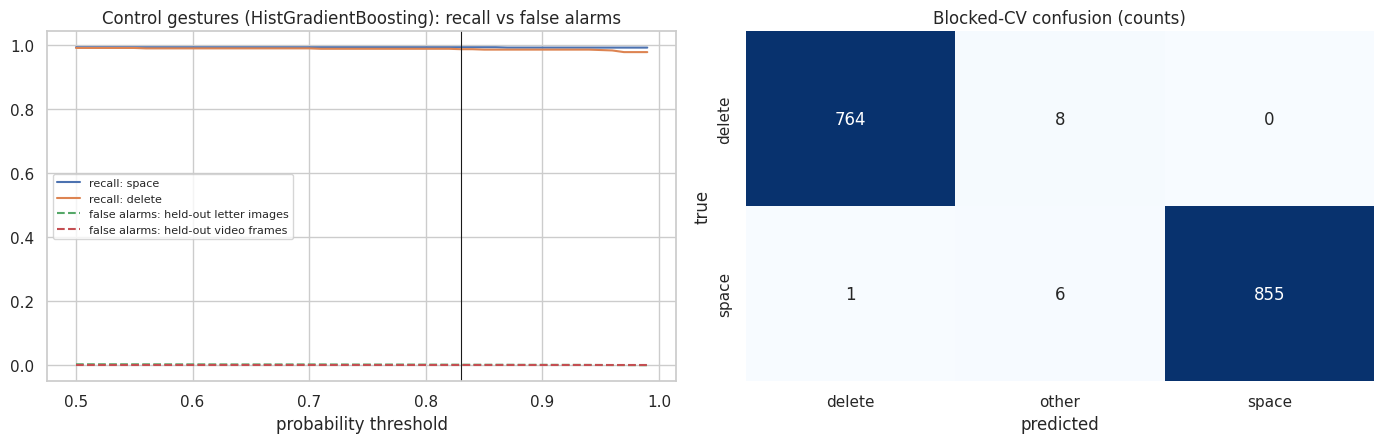

In [9]:
oof, fps = CV[BEST]; ths = np.round(np.arange(0.5, 0.996, 0.01), 3)
tab = pd.DataFrame([{'tau': t, **ctrl_metrics(oof, fps, t)} for t in ths])
ok_ = tab[(tab['false_alarm_letters'] <= 0.002) & (tab['false_alarm_dynamic_frames'] <= 0.002)]
CTRL_TAU = float(ok_['tau'].iloc[0]) if len(ok_) else 0.95
print('Chosen control threshold (smallest with <= 0.2% false alarms on held-out frames):', CTRL_TAU); display(tab[tab['tau'].isin([0.5, 0.7, 0.8, 0.9, 0.95, 0.99])].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(tab['tau'], tab['recall_space'], label='recall: space'); axes[0].plot(tab['tau'], tab['recall_delete'], label='recall: delete')
axes[0].plot(tab['tau'], tab['false_alarm_letters'], '--', label='false alarms: held-out letter images'); axes[0].plot(tab['tau'], tab['false_alarm_dynamic_frames'], '--', label='false alarms: held-out video frames')
axes[0].axvline(CTRL_TAU, color='k', lw=.8); axes[0].set_xlabel('probability threshold'); axes[0].set_title(f'Control gestures ({BEST}): recall vs false alarms'); axes[0].legend(fontsize=8)
pred_oof = np.array(CT)[oof.argmax(1)]; cmt = pd.crosstab(P_y, pred_oof).reindex(index=['delete', 'space'], columns=CT, fill_value=0)
sns.heatmap(cmt.div(cmt.sum(1), axis=0), annot=cmt.values, fmt='d', cmap='Blues', vmin=0, vmax=1, ax=axes[1], cbar=False); axes[1].set_title('Blocked-CV confusion (counts)'); axes[1].set_xlabel('predicted'); axes[1].set_ylabel('true')
plt.tight_layout(); plt.savefig(f'{OUT}/p2_18_control_gestures.png', dpi=130, bbox_inches='tight'); plt.show()

In [10]:
final_ctrl = fit_ctrl(BEST, P_X, P_y, neg_tr)
joblib.dump(final_ctrl, f'{MODELS}/control_gesture_clf.joblib', compress=3)
pf = final_ctrl.predict_proba(HO_static); pdyn = final_ctrl.predict_proba(HO_dyn)
print('Final control model size (MB):', round(os.path.getsize(f'{MODELS}/control_gesture_clf.joblib') / 1e6, 2))
print(f'False alarms at tau={CTRL_TAU}: held-out letters {(np.maximum(pf[:,0], pf[:,2]) >= CTRL_TAU).mean():.4f} | held-out video frames {(np.maximum(pdyn[:,0], pdyn[:,2]) >= CTRL_TAU).mean():.4f}')
print('Training data came from:', dict(ctrl.groupby('person').size()))

Final control model size (MB): 0.3
False alarms at tau=0.83: held-out letters 0.0048 | held-out video frames 0.0000
Training data came from: {'aamina': np.int64(567), 'fahad': np.int64(472), 'wisha': np.int64(595)}


**What it tells us:** the left plot shows the trade-off: a higher threshold removes false alarms but misses more real gestures; the threshold marked is the smallest one that keeps false alarms on unseen people's letters under 0.2% per frame. Because the typing engine additionally needs several consecutive frames, the false-alarm rate per *event* is far lower. Remember that the recall numbers come from a single recorded person.

## 4. Dynamic model, final version
The Random Forest (best by cross-validation in step 4) is first retrained on the same train + val videos as before as a sanity check (it must reproduce the test result), then retrained on **all 393 videos** for deployment.

In [11]:
dyn_f = lambda idx: eng.dynamic_features(Xv[idx], Mv[idx])
rf_dev = RandomForestClassifier(400, random_state=0, n_jobs=-1).fit(dyn_f(dev_v), yv[dev_v])
acc = (rf_dev.predict(dyn_f(te_v)) == yv[te_v]).mean(); print('Sanity check, trained on train+val, test accuracy:', round(acc, 4), '(step 4 reported 1.0)')
rf_final = RandomForestClassifier(400, random_state=0, n_jobs=-1).fit(dyn_f(np.ones(len(Xv), bool)), yv)
joblib.dump(rf_final, f'{MODELS}/dynamic_rf.joblib', compress=3); print('dynamic_rf.joblib size (MB):', round(os.path.getsize(f'{MODELS}/dynamic_rf.joblib') / 1e6, 2), '| classes:', DYNAMIC)

Sanity check, trained on train+val, test accuracy: 1.0 (step 4 reported 1.0)
dynamic_rf.joblib size (MB): 0.28 | classes: ['2-Hay', 'Alifmad', 'Aray', 'Jeem']


## 5. Router: still hand or moving hand?
**Motion measure:** for a short window of landmark vectors, the largest distance of any frame from the window's mean pose. A held letter gives a tiny value (only tracking jitter); a dynamic letter gives a large one.

**Calibration with real data:** *still* windows come from your recorded holds (4 consecutive samples, about 0.4 s, deliberately a bit longer than the video windows, so jitter is overestimated rather than underestimated); *moving* windows come from the dynamic videos (16 frames, about 0.35 s). The threshold is placed between the 99th percentile of still windows and the 5th percentile of the peak motion of each video. The web app will repeat this calibration live for 3 seconds with the user's own still hand.

still windows: median 0.0108, 99th pct 0.3264 | dynamic videos peak motion: 5th pct 0.0328, median 0.1443
Separated: False | router threshold TAU = 0.3264


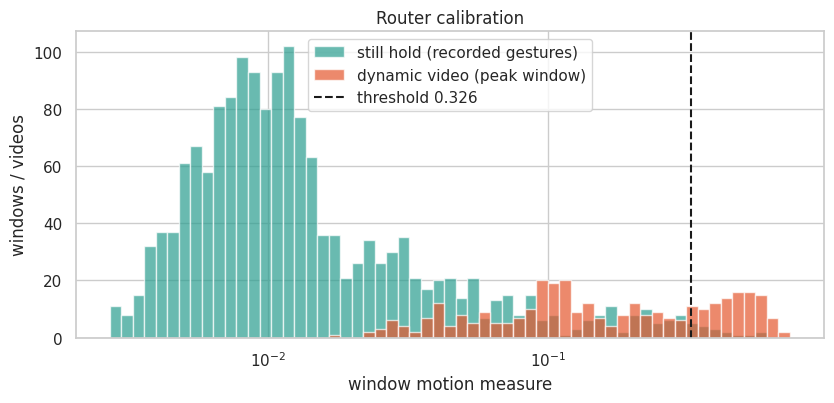

In [12]:
still_ext = []
for _, g in pos.groupby(['person', 'session', 'label']):
    F = g[FEAT].values.astype(np.float32)
    still_ext += [eng.window_extent(F[s:s + 4]) for s in range(0, len(F) - 3)]
still_ext = np.array(still_ext)
peaks = []
for i in np.where(dev_v)[0]:
    ex = [eng.window_extent(Xv[i][s:s + 16]) for s in range(0, 88 - 15, 2) if Mv[i][s:s + 16].all()]
    if ex: peaks.append(max(ex))
peaks = np.array(peaks); q99, q05 = np.quantile(still_ext, .99), np.quantile(peaks, .05)
TAU = float(np.sqrt(q99 * q05)) if q05 > q99 else float(q99)
print(f'still windows: median {np.median(still_ext):.4f}, 99th pct {q99:.4f} | dynamic videos peak motion: 5th pct {q05:.4f}, median {np.median(peaks):.4f}')
print('Separated:', q05 > q99, '| router threshold TAU =', round(TAU, 4))
fig, ax = plt.subplots(figsize=(8.5, 4.2)); bins = np.logspace(np.log10(min(still_ext.min(), peaks.min()) + 1e-4), np.log10(max(still_ext.max(), peaks.max())), 60)
ax.hist(still_ext, bins=bins, alpha=.7, label='still hold (recorded gestures)', color='#2A9D8F'); ax.hist(peaks, bins=bins, alpha=.7, label='dynamic video (peak window)', color='#E4572E')
ax.axvline(TAU, color='k', ls='--', label=f'threshold {TAU:.3f}'); ax.set_xscale('log'); ax.set_xlabel('window motion measure'); ax.set_ylabel('windows / videos'); ax.legend(); ax.set_title('Router calibration')
plt.tight_layout(); plt.savefig(f'{OUT}/p2_19_router_calibration.png', dpi=130, bbox_inches='tight'); plt.show()

In [13]:
def run_router(vecs, window, still_frames=8, min_seg=20):
    R = eng.MotionRouter(TAU, window=window, still_frames=still_frames, min_segment=min_seg); segs = []
    for v in vecs:
        _, seg = R.update(v)
        if seg is not None: segs.append(seg)
    _, seg = R.update(None)
    if seg is not None: segs.append(seg)
    return segs

# (a) dynamic test videos: does the router find the gesture, and does the Random Forest classify the extracted segment correctly?
found, correct_seg, nseg = 0, 0, []
test_ids = np.where(te_v)[0]
for i in test_ids:
    segs = run_router([Xv[i][t] if Mv[i][t] else None for t in range(88)], window=16); nseg.append(len(segs))
    if segs:
        found += 1; Xs, Ms = eng.resample_segment(max(segs, key=len), 88)
        correct_seg += int(rf_dev.predict(eng.dynamic_features(Xs[None], Ms[None]))[0] == yv[i])
print(f'Dynamic test videos: segment found in {found}/{len(test_ids)} ({found / len(test_ids):.1%}); segments per video mean {np.mean(nseg):.2f}')
print(f'Classified correctly from the ROUTER segment: {correct_seg}/{found} ({correct_seg / max(found, 1):.1%})')
# (b) still holds: the router must stay quiet
false_motion, n_streams, frames_total = 0, 0, 0
for _, g in pos.groupby(['person', 'session', 'label']):
    F = g[FEAT].values.astype(np.float32); n_streams += 1; frames_total += len(F)
    false_motion += len(run_router(list(F), window=4, still_frames=4, min_seg=8))
print(f'Still-hold recordings: {false_motion} false motion segments in {n_streams} recordings ({frames_total} frames)')

Dynamic test videos: segment found in 13/59 (22.0%); segments per video mean 0.22
Classified correctly from the ROUTER segment: 12/13 (92.3%)
Still-hold recordings: 2 false motion segments in 6 recordings (1634 frames)


**What it tells us:** the first number says how many dynamic gestures the router isolates by itself, and the second whether the isolated segment is still classified correctly (this is the end-to-end dynamic route). The last line says how often a held hand is wrongly treated as a gesture. Because the videos were resampled in Phase 1 and the recordings are at 10 Hz, these are indicative values; the live app recalibrates the threshold.

## 6. Simulation of the whole typing pipeline
**Words:** 300 words from a small demo lexicon (best case: every word is in the dictionary) and 200 random letter strings that are *not* in the lexicon (worst case, like names the dictionary does not know). Real use lies in between.

**Frames:** each letter is a hold of 14–24 frames built from two real **test** images of the same person (so a wrong prediction persists for several frames, like a real held sign), preceded sometimes by 1–2 glitch frames of another letter (the hand moving into position) and followed by neutral frames (no hand). Dynamic letters are one-shot events from real test videos. In 15% of letters a wrong letter is typed first and removed with the delete gesture, and every word ends with the space gesture (frames from the cross-validation predictions of the recorded gestures).

**Decision per frame:** exactly the pipeline described at the top (control classifier first, then the static model; no hand detected means neutral). Static models: MobileNetV2 and the 3-model ensemble.

In [14]:
LEX_RAW = '''علی احمد حسن حسین عمر بلال فاطمہ زینب مریم سارہ ماریہ ثنا رضا عباس حمزہ سلمان عثمان فہد آمنہ اقبال جناح قائد نور سعد زید یوسف ابراہیم اسماعیل خالد طارق کامران عدنان فیصل ندیم نعمان وقار شاہد
پاکستان لاہور کراچی پشاور ملتان اسلام آباد سندھ پنجاب بلوچستان سکول کتاب قلم پانی روٹی دودھ چائے گھر دوست ماں باپ بہن بیٹا بیٹی استاد طالب علم کام دن رات صبح شام سورج چاند ستارہ آسمان زمین پھول درخت پرندہ شیر بلی کتا گھوڑا گائے بکری مچھلی سیب آم کیلا انار انگور چاول دال گوشت نمک چینی دکان بازار شہر ملک قوم زبان اردو پاک صاف اچھا برا بڑا چھوٹا نیا پرانا سرخ نیلا پیلا سبز کالا سفید ایک دو تین چار پانچ سات آٹھ دس سلام شکریہ خدا اللہ دل دماغ آنکھ ناک کان ہاتھ پاؤں بال منہ سر کرسی میز کمرہ دروازہ کھڑکی کپڑا جوتا ٹوپی گھڑی فون کمپیوٹر گاڑی سڑک پل ریل جہاز سمندر دریا پہاڑ جنگل بادل بارش ہوا آگ برف سردی گرمی موسم مہینہ سال ہفتہ جمعہ اتوار پیر منگل بدھ جمعرات'''
lexicon = eng.Lexicon(LEX_RAW.split())
dropped = [w for w in set(LEX_RAW.split()) if w not in lexicon.words]
print('Lexicon words kept:', len(lexicon.words), '| dropped (use letters outside the 40-letter alphabet):', dropped)
open(f'{OUT}/urdu_lexicon.txt', 'w', encoding='utf-8').write('\n'.join(sorted(lexicon.words)))

SP = np.load(f'{WORK}/static_test_predictions.npz', allow_pickle=True); DPz = np.load(f'{WORK}/dynamic_test_predictions.npz', allow_pickle=True)
print('static prediction keys:', list(SP.keys()), '| dynamic:', list(DPz.keys()))
assert (SP['y'] == te_s['class_id'].values).all() and (SP['subject'] == te_s['subject'].values).all(), 'test order mismatch'
assert (DPz['y'] == yv[te_v]).all(), 'dynamic test order mismatch'
P_STATIC = {'MobileNetV2': SP['MobileNetV2'].astype('float32'), 'Ensemble': SP['Ensemble_(3_models)'].astype('float32')}
P_DYN = DPz['RF'].astype('float32')

pc_te = np.full((len(te_s), 3), np.nan, np.float32); pc_te[det_te] = final_ctrl.predict_proba(L_te[det_te])
PS_TE, PD_TE = pc_te[:, 2], pc_te[:, 0]                       # control probabilities of every test letter image
oof_pool = {'space': oof[P_y == 'space'][:, [0, 2]], 'delete': oof[P_y == 'delete'][:, [0, 2]]}   # columns: p_delete, p_space (held-out predictions)

Lexicon words kept: 170 | dropped (use letters outside the 40-letter alphabet): ['چائے', 'پاؤں', 'گائے', 'قائد']
static prediction keys: ['Baseline_CNN', 'MobileNetV2', 'EfficientNet-B0', 'Ensemble_(3_models)', 'y', 'subject', 'original'] | dynamic: ['RF', 'LSTM', 'CNN1D', 'GRU', 'MLP', 'y', 'files']


In [15]:
import bisect
cls_name = np.array(STATIC)[te_s['class_id'].values]; subj = te_s['subject'].values
pool = defaultdict(lambda: defaultdict(list))
for i, (c, s) in enumerate(zip(cls_name, subj)): pool[c][s].append(i)
dyn_pool = defaultdict(list)
for j, c in enumerate(np.array(DYNAMIC)[yv[te_v]]): dyn_pool[c].append(j)
ALL_STATIC_IDX = np.arange(len(te_s))

def static_hold(cls, rng):
    subs = [s for s, ix in pool[cls].items() if len(ix) >= 2] or list(pool[cls])
    s = subs[rng.integers(len(subs))]; ix = pool[cls][s]; a, b = ix[rng.integers(len(ix))], ix[rng.integers(len(ix))]
    n = int(rng.integers(14, 25)); return [('S', a)] * (n // 2) + [('S', b)] * (n - n // 2)
def control_hold(kind, rng):
    n = int(rng.integers(12, 19)); k = rng.integers(len(oof_pool[kind]), size=2); return [('C', kind, int(k[0]))] * (n // 2) + [('C', kind, int(k[1]))] * (n - n // 2)
def gap(rng): return [('N',)] * int(rng.integers(4, 9))

def build_stream(word, rng, p_wrong=0.15, p_glitch=0.3):
    classes = [eng.CHAR_TO_CLASS[ch] for ch in word]; frames, marks, n_del = [], [], 0
    for cls in classes:
        if rng.random() < p_glitch: frames += [('S', int(rng.choice(ALL_STATIC_IDX)))] * int(rng.integers(1, 3))
        if rng.random() < p_wrong:                                              # wrong letter, then delete it
            wrong = [c for c in STATIC if c != cls][rng.integers(len(STATIC) - 1)]
            frames += static_hold(wrong, rng) + gap(rng) + control_hold('delete', rng) + gap(rng); n_del += 1
        marks.append((len(frames), cls))
        frames += ([('D', int(rng.choice(dyn_pool[cls])))] if cls in DYNAMIC else static_hold(cls, rng)) + gap(rng)
    frames += control_hold('space', rng) + gap(rng)
    return {'frames': frames, 'gt': word, 'marks': marks, 'n_delete': n_del}

def to_events(frames, model, ctrl_thr):
    Pst = P_STATIC[model]; ev = []
    for fr in frames:
        t = fr[0]
        if t == 'N': ev.append(('none', None, 0.0))
        elif t == 'S':
            i = fr[1]; ev.append(eng.decide_event(bool(det_te[i]), PS_TE[i], PD_TE[i], Pst[i], STATIC, ctrl_thr))
        elif t == 'D':
            pr = P_DYN[fr[1]]; k = int(pr.argmax()); ev.append(('dynamic', DYNAMIC[k], float(pr[k])))
        else:
            pd_, ps_ = oof_pool[fr[1]][fr[2]]; ev.append(eng.decide_event(True, ps_, pd_, np.ones(len(STATIC)) / len(STATIC), STATIC, ctrl_thr))
    return ev

def run_stream(stream, events, cfg):
    typer = eng.SignTyper(cfg, lexicon); acts = []
    for t, (k, l, c) in enumerate(events):
        a = typer.step(k, l, c)
        if a: acts.append((t, a))
    final = typer.final_text(); raw = ' '.join(r for r, _ in typer.words)
    starts = [m[0] for m in stream['marks']]
    delays = [t - starts[max(bisect.bisect_right(starts, t) - 1, 0)] for t, a in acts if a['action'] == 'letter']
    n_sp = sum(a['action'] == 'space' for _, a in acts); n_dl = sum(a['action'] == 'delete' for _, a in acts)
    return {'final': final, 'raw': raw, 'delay': np.mean(delays) if delays else np.nan, 'extra_space': max(n_sp - 1, 0), 'extra_delete': max(n_dl - stream['n_delete'], 0),
            'missed_delete': max(stream['n_delete'] - n_dl, 0)}

rng = np.random.default_rng(7)
lex_words = [str(w) for w in rng.choice(sorted(w for w in lexicon.words if 3 <= len(w) <= 7), 300, replace=True)]
alphabet = sorted(eng.ALPHABET); oov_words = []
while len(oov_words) < 200:
    w = ''.join(rng.choice(alphabet, int(rng.integers(3, 7))));
    if w not in lexicon.words: oov_words.append(w)
STREAMS = {'lexicon': [build_stream(w, rng) for w in lex_words], 'OOV': [build_stream(w, rng) for w in oov_words]}
EVENTS = {(m, s): [to_events(st['frames'], m, CTRL_TAU) for st in STREAMS[s]] for m in P_STATIC for s in STREAMS}
print('Streams:', {k: len(v) for k, v in STREAMS.items()}, '| mean frames per stream:', int(np.mean([len(s['frames']) for v in STREAMS.values() for s in v])))

Streams: {'lexicon': 300, 'OOV': 200} | mean frames per stream: 151


In [16]:
def evaluate(model, cfg):
    out = {}
    for s in STREAMS:
        res = [run_stream(st, ev, cfg) for st, ev in zip(STREAMS[s], EVENTS[(model, s)])]
        gt = [st['gt'] for st in STREAMS[s]]
        out[s] = {'word_acc': np.mean([r['final'] == g for r, g in zip(res, gt)]), 'word_acc_raw': np.mean([r['raw'] == g for r, g in zip(res, gt)]),
                  'cer': np.mean([eng.edit_distance(r['final'], g) / len(g) for r, g in zip(res, gt)]), 'delay_frames': np.nanmean([r['delay'] for r in res]),
                  'extra_space': np.mean([r['extra_space'] for r in res]), 'extra_delete': np.mean([r['extra_delete'] for r in res]), 'missed_delete': np.mean([r['missed_delete'] for r in res]),
                  'overcorrected': np.mean([(r['raw'] == g) and (r['final'] != g) for r, g in zip(res, gt)]), 'fixed': np.mean([(r['raw'] != g) and (r['final'] == g) for r, g in zip(res, gt)])}
    return out

rows = []
for model in P_STATIC:
    for lc in (0.5, 0.7, 0.9):
        for sf in (3, 5, 8, 12):
            for corr in (False, True):
                cfg = eng.TyperConfig(letter_conf=lc, stable_frames=sf, control_conf=CTRL_TAU, correct_words=corr)
                for s, m in evaluate(model, cfg).items(): rows.append({'model': model, 'letter_conf': lc, 'stable_frames': sf, 'correction': corr, 'set': s, **m})
SW = pd.DataFrame(rows); print('Sweep rows:', len(SW)); SW.head()

Sweep rows: 96


,model,letter_conf,stable_frames,correction,set,word_acc,word_acc_raw,cer,delay_frames,extra_space,extra_delete,missed_delete,overcorrected,fixed
0,MobileNetV2,0.5,3,False,lexicon,0.550,0.550,0.140190,2.998520,0.003333,0.000,0.013333,0.00,0.00
1,MobileNetV2,0.5,3,False,OOV,0.415,0.415,0.169333,2.826325,0.005000,0.015,0.020000,0.00,0.00
2,MobileNetV2,0.5,3,True,lexicon,0.800,0.550,0.076746,2.998520,0.003333,0.000,0.013333,0.00,0.25
3,MobileNetV2,0.5,3,True,OOV,0.405,0.415,0.177833,2.826325,0.005000,0.015,0.020000,0.01,0.00
4,MobileNetV2,0.5,5,False,lexicon,0.550,0.550,0.140190,4.842192,0.003333,0.000,0.013333,0.00,0.00


,model,letter_conf,stable_frames,cer_OOV,cer_lexicon,delay_frames_OOV,delay_frames_lexicon,word_acc_OOV,word_acc_lexicon,mean_word_acc
0,Ensemble,0.5,3,0.1535,0.0699,2.8727,2.8530,0.480,0.8100,0.6450
1,Ensemble,0.5,5,0.1535,0.0699,4.7251,4.6868,0.480,0.8100,0.6450
2,Ensemble,0.5,8,0.1605,0.0830,7.4053,7.4630,0.460,0.7733,0.6167
12,MobileNetV2,0.5,3,0.1778,0.0767,2.8263,2.9985,0.405,0.8000,0.6025
13,MobileNetV2,0.5,5,0.1778,0.0767,4.6813,4.8422,0.405,0.8000,0.6025
14,MobileNetV2,0.5,8,0.1787,0.0874,7.4208,7.6830,0.405,0.7700,0.5875
17,MobileNetV2,0.7,5,0.1844,0.0969,4.9058,4.7753,0.390,0.7433,0.5667
16,MobileNetV2,0.7,3,0.1844,0.0969,3.0562,2.9457,0.390,0.7433,0.5667


CHOSEN: {'static_model': 'Ensemble', 'letter_conf': 0.5, 'stable_frames': 3}


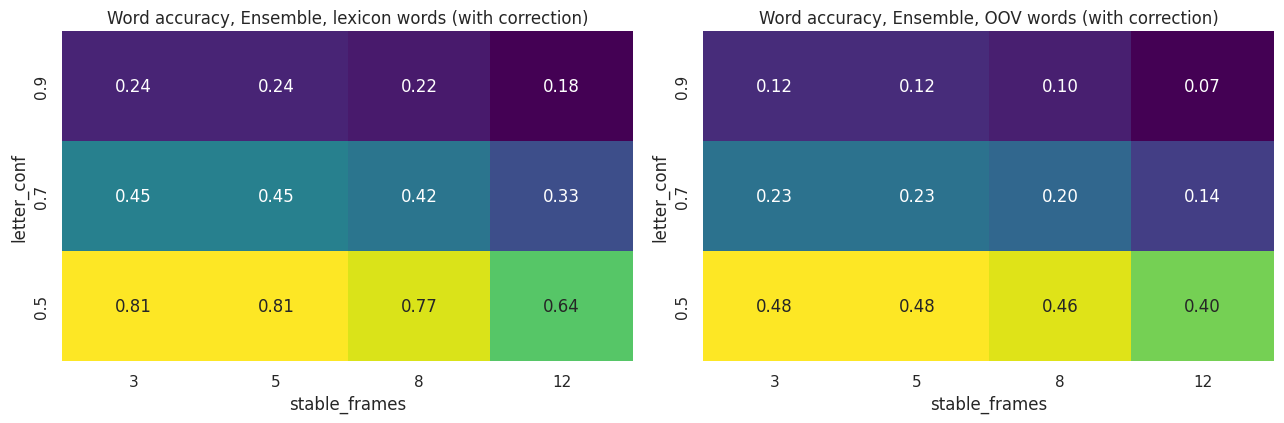

In [17]:
# Choose the setting: best mean word accuracy (with correction, over both word sets) among settings with stable_frames <= 8
piv = SW[SW['correction']].pivot_table(index=['model', 'letter_conf', 'stable_frames'], columns='set', values=['word_acc', 'cer', 'delay_frames']).reset_index()
piv.columns = ['_'.join(c).strip('_') for c in piv.columns]; piv['mean_word_acc'] = (piv['word_acc_lexicon'] + piv['word_acc_OOV']) / 2
cand = piv[piv['stable_frames'] <= 8].sort_values('mean_word_acc', ascending=False); display(cand.head(8).round(4))
B = cand.iloc[0]; BEST_CFG = {'static_model': B['model'], 'letter_conf': float(B['letter_conf']), 'stable_frames': int(B['stable_frames'])}; print('CHOSEN:', BEST_CFG)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, s in zip(axes, ['lexicon', 'OOV']):
    t = SW[(SW.model == BEST_CFG['static_model']) & SW.correction & (SW.set == s)].pivot(index='letter_conf', columns='stable_frames', values='word_acc')
    sns.heatmap(t, annot=True, fmt='.2f', cmap='viridis', ax=ax, cbar=False); ax.set_title(f"Word accuracy, {BEST_CFG['static_model']}, {s} words (with correction)"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(f'{OUT}/p2_20_pipeline_sweep.png', dpi=130, bbox_inches='tight'); plt.show()

,word_acc (without correction),word_acc (with correction),cer (without correction),cer (with correction)
set,,,,
OOV,0.4900,0.48,0.1473,0.1535
lexicon,0.6233,0.81,0.1141,0.0699


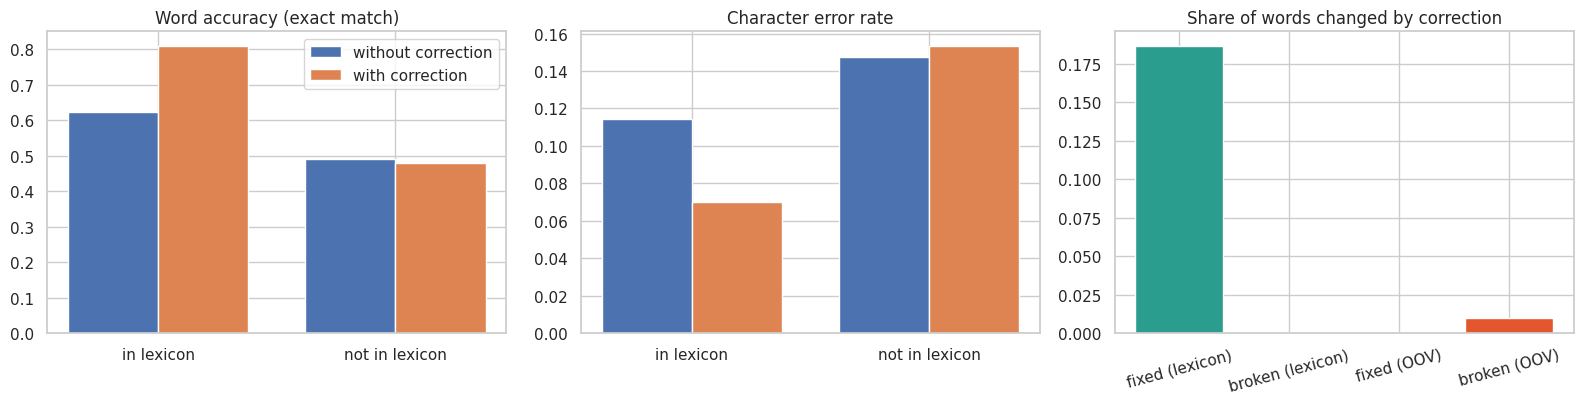

Control behaviour at the chosen setting (per stream): extra spaces 0.0042 | extra deletes 0.0075 | missed deletes 0.02
Mean delay from the start of a hold to the commit (frames): 2.9 | at 15 fps = 0.19 s


In [18]:
b = SW[(SW.model == BEST_CFG['static_model']) & (SW.letter_conf == BEST_CFG['letter_conf']) & (SW.stable_frames == BEST_CFG['stable_frames'])]
tbl = b.pivot(index='set', columns='correction', values=['word_acc', 'cer']).round(4); tbl.columns = [f"{a} ({'with' if c else 'without'} correction)" for a, c in tbl.columns]; display(tbl)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2)); xs = np.arange(2); w = .38
for k, corr in enumerate([False, True]):
    d = b[b.correction == corr].set_index('set').loc[['lexicon', 'OOV']]
    axes[0].bar(xs + (k - .5) * w, d['word_acc'], w, label=('with' if corr else 'without') + ' correction'); axes[1].bar(xs + (k - .5) * w, d['cer'], w)
for ax, t in zip(axes[:2], ['Word accuracy (exact match)', 'Character error rate']): ax.set_xticks(xs); ax.set_xticklabels(['in lexicon', 'not in lexicon']); ax.set_title(t)
axes[0].legend(); d = b[b.correction].set_index('set').loc[['lexicon', 'OOV']]
axes[2].bar(['fixed (lexicon)', 'broken (lexicon)', 'fixed (OOV)', 'broken (OOV)'], [d.loc['lexicon', 'fixed'], d.loc['lexicon', 'overcorrected'], d.loc['OOV', 'fixed'], d.loc['OOV', 'overcorrected']], color=['#2A9D8F', '#E4572E', '#2A9D8F', '#E4572E'])
axes[2].set_title('Share of words changed by correction'); axes[2].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.savefig(f'{OUT}/p2_21_dictionary_effect.png', dpi=130, bbox_inches='tight'); plt.show()
print('Control behaviour at the chosen setting (per stream): extra spaces', round(b[b.correction].extra_space.mean(), 4), '| extra deletes', round(b[b.correction].extra_delete.mean(), 4), '| missed deletes', round(b[b.correction].missed_delete.mean(), 4))
print('Mean delay from the start of a hold to the commit (frames):', round(b[b.correction].delay_frames.mean(), 1), '| at 15 fps =', round(b[b.correction].delay_frames.mean() / 15, 2), 's')

**What it tells us:** word accuracy is much lower than letter accuracy, because one wrong letter spoils a whole word (a 5-letter word with 87% letter accuracy is right only about half of the time). The dictionary can repair some single-letter errors, but only for words it knows; for unknown words (names) correction can do nothing, and the right-hand chart shows how often it wrongly changed a correct word.

## 7. Save everything

In [19]:
config = {'static_model': BEST_CFG['static_model'], 'typer': {'letter_conf': BEST_CFG['letter_conf'], 'stable_frames': BEST_CFG['stable_frames'], 'dynamic_conf': 0.6,
          'control_conf': CTRL_TAU, 'control_frames': 8, 'neutral_frames': 3, 'require_neutral': 'same', 'correct_words': True, 'max_dist': 1},
          'router': {'tau': TAU, 'window_seconds': 0.35, 'still_frames': 8, 'min_segment': 20}, 'control_classifier': BEST, 'ctrl_threshold': CTRL_TAU,
          'files': {'control': 'control_gesture_clf.joblib', 'dynamic_rf': 'dynamic_rf.joblib', 'lexicon': 'urdu_lexicon.txt', 'engine': 'typing_engine.py'}}
json.dump(config, open(f'{OUT}/pipeline_config.json', 'w'), indent=1)
SW.to_csv(f'{OUT}/pipeline_simulation_sweep.csv', index=False); cmp_.to_csv(f'{OUT}/control_classifier_comparison.csv', index=False); tab.to_csv(f'{OUT}/control_threshold_table.csv', index=False)
shutil.copy('/content/typing_engine.py', f'{OUT}/typing_engine.py')
for f in os.listdir(MODELS): shutil.copy(f'{MODELS}/{f}', f'{DRIVE_DIR}/models/{f}')
for f in os.listdir(OUT):
    if os.path.isfile(f'{OUT}/{f}'): shutil.copy(f'{OUT}/{f}', f'{DRIVE_DIR}/results/{f}')
print(sorted(os.listdir(OUT)), sorted(os.listdir(MODELS)))

['control_classifier_comparison.csv', 'control_threshold_table.csv', 'models', 'p2_18_control_gestures.png', 'p2_19_router_calibration.png', 'p2_20_pipeline_sweep.png', 'p2_21_dictionary_effect.png', 'pipeline_config.json', 'pipeline_simulation_sweep.csv', 'typing_engine.py', 'urdu_lexicon.txt'] ['control_gesture_clf.joblib', 'dynamic_rf.joblib']


In [20]:
def hdr(t): print('\n' + '=' * 70 + f'\n{t}\n' + '=' * 70)
hdr('Control gesture data'); print(ctrl.groupby(['person', 'label']).size().to_string())
hdr('Hand detection on letter images'); print(f'train sample {det_tr.mean():.3f} | test {det_te.mean():.3f}')
hdr('Control classifier comparison (threshold 0.9)'); print(cmp_.round(4).to_string(index=False)); print('Chosen:', BEST, '| threshold', CTRL_TAU)
print(tab[tab['tau'].isin([0.5, 0.7, 0.8, 0.9, 0.95, 0.99])].round(4).to_string(index=False))
hdr('Dynamic RF'); print('sanity test accuracy', round(acc, 4))
hdr('Router'); print(f'still q99 {q99:.4f} | dynamic peak q05 {q05:.4f} | TAU {TAU:.4f}'); print(f'segments found {found}/{len(test_ids)}, correct from segment {correct_seg}/{found}; false motion segments in still holds: {false_motion} / {n_streams} recordings')
hdr('Simulation, chosen setting'); print(BEST_CFG); print(tbl.to_string())
print(b[b.correction][['set', 'word_acc_raw', 'fixed', 'overcorrected', 'delay_frames', 'extra_space', 'extra_delete', 'missed_delete']].round(4).to_string(index=False))
hdr('Top sweep settings'); print(cand.head(6).round(4).to_string(index=False))
hdr('Per-model comparison at the chosen letter_conf and stable_frames')
print(SW[(SW.letter_conf == BEST_CFG['letter_conf']) & (SW.stable_frames == BEST_CFG['stable_frames']) & SW.correction].groupby(['model', 'set'])[['word_acc', 'cer']].mean().round(4).to_string())
hdr('Files'); print(sorted(os.listdir(OUT)), sorted(os.listdir(MODELS)))


Control gesture data
person  label 
aamina  delete    273
        space     294
fahad   delete    203
        space     269
wisha   delete    296
        space     299

Hand detection on letter images
train sample 0.963 | test 0.956

Control classifier comparison (threshold 0.9)
               model  threshold  recall_space  recall_delete  false_alarm_letters  false_alarm_dynamic_frames  score
        RandomForest        0.9        0.9490         0.9326               0.0000                         0.0 0.9408
HistGradientBoosting        0.9        0.9907         0.9845               0.0016                         0.0 0.9714
Chosen: HistGradientBoosting | threshold 0.83
 tau  recall_space  recall_delete  false_alarm_letters  false_alarm_dynamic_frames
0.50        0.9919         0.9896               0.0034                         0.0
0.70        0.9919         0.9883               0.0028                         0.0
0.80        0.9919         0.9870               0.0022                   

In [21]:
persons = pos['person'].values; rows = []
for p in np.unique(persons):
    tr, te_ = persons != p, persons == p
    clf = fit_ctrl(BEST, P_X[tr], P_y[tr], neg_tr); pr = clf.predict_proba(P_X[te_])
    ho = np.concatenate([clf.predict_proba(HO_static), clf.predict_proba(HO_dyn)])
    rows.append({'held_out_person': p,
                 'recall_space': (pr[P_y[te_] == 'space'][:, 2] >= CTRL_TAU).mean(),
                 'recall_delete': (pr[P_y[te_] == 'delete'][:, 0] >= CTRL_TAU).mean(),
                 'false_alarm': (np.maximum(ho[:, 0], ho[:, 2]) >= CTRL_TAU).mean()})
pd.DataFrame(rows).round(4)

,held_out_person,recall_space,recall_delete,false_alarm
0,aamina,1.0000,0.9817,0.0002
1,fahad,0.9740,0.8916,0.0002
2,wisha,0.9967,0.9730,0.0002
